In [550]:
meditation

,Unnamed: 0,duration_in_seconds,site,age,gender,country_birth,job,condition,stress
103,246,1282,gold,20,2.0,England,NaN,Loving kindness,1.30
2081,6210,1289,seeb,23,2.0,Germany,NaN,Control (book chapter),1.90
451,1113,1695,wurz,18,2.0,Germany,NaN,Mindful walking,2.95
1056,2856,1409,jose,18,2.0,United States of America,NaN,Control (book chapter),2.75
283,667,13363,loyo,20 years old,2.0,United States,A student,Mindful walking,1.50
...,...,...,...,...,...,...,...,...,...
326,772,2304,indi,18,2.0,America,NaN,Mindful walking,1.75
1493,4145,1522,glen,50,1.0,USA,NaN,Mindful breathing,1.55
1365,3774,1408,loyo,20,1.0,Usa,NaN,Mindful breathing,1.20
1965,5762,1433,olaf,21 years,2.0,United States of America,NaN,Loving kindness,2.50


In [561]:
meditation = pd.read_csv('data/meditation-stress-sample.csv')

In [562]:
alt.Chart(meditation).mark_bar().encode(
    y='condition',
    x='count()',
    color='gender'
)

alt.Chart(...)

recode gender as male female and drop? everything else. make sure to update subset.
include conclusions form this note that maybe this study does not apply as much to the less frequent gender (mention authors)

then show how bars are similar ot areas in that they can be great when the total is important but not when cmoparison between groups matter and emphasize shared baseline

include a warning with areas too that they are not good for comparing without shared baseline?

In [528]:
from altair.datasets import data

dmovies = data.movies()
dmovies

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,146083,146083,<NA>,8000000,1998-06-12,R,<NA>,Gramercy,<NA>,<NA>,<NA>,<NA>,<NA>,6.1,1071
1,"First Love, Last Rites",10876,10876,<NA>,300000,1998-08-07,R,<NA>,Strand,<NA>,Drama,<NA>,<NA>,<NA>,6.9,207
2,I Married a Strange Person,203134,203134,<NA>,250000,1998-08-28,<NA>,<NA>,Lionsgate,<NA>,Comedy,<NA>,<NA>,<NA>,6.8,865
3,Let's Talk About Sex,373615,373615,<NA>,300000,1998-09-11,<NA>,<NA>,Fine Line,<NA>,Comedy,<NA>,<NA>,13,<NA>,<NA>
4,Slam,1009819,1087521,<NA>,1000000,1998-10-09,R,<NA>,Trimark,Original Screenplay,Drama,Contemporary Fiction,<NA>,62,3.4,165
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3196,Zack and Miri Make a Porno,31452765,36851125,21240321,24000000,2008-10-31,R,101,Weinstein Co.,Original Screenplay,Comedy,Contemporary Fiction,Kevin Smith,65,7.0,55687
3197,Zodiac,33080084,83080084,20983030,85000000,2007-03-02,R,157,Paramount Pictures,Based on Book/Short Story,Thriller/Suspense,Dramatization,David Fincher,89,<NA>,<NA>
3198,Zoom,11989328,12506188,6679409,35000000,2006-08-11,PG,<NA>,Sony Pictures,Based on Comic/Graphic Novel,Adventure,Super Hero,Peter Hewitt,3,3.4,7424
3199,The Legend of Zorro,45575336,141475336,<NA>,80000000,2005-10-28,PG,129,Sony Pictures,Remake,Adventure,Historical Fiction,Martin Campbell,26,5.7,21161


In [480]:
import pandas as pd

movies = pd.read_json('https://raw.githubusercontent.com/joelostblom/teaching-datasets/main/movies.json')

movies['genre']

,id,title,runtime,budget,revenue,genres,countries,vote_average,vote_loved_it,vote_count,vote_std
0,12,Finding Nemo,100,94000000,940335536,[Animation],[United States of America],3.86,0.322,33887,0.87
1,22,Pirates of the Caribbean: The Curse of the Bla...,143,140000000,655011224,[Fantasy],[United States of America],3.81,0.320,36337,0.91
2,35,The Simpsons Movie,87,75000000,527068851,[Animation],[United States of America],3.44,0.155,8621,0.92
3,58,Pirates of the Caribbean: Dead Man's Chest,151,200000000,1065659812,[Fantasy],[United States of America],3.47,0.198,15079,0.98
4,75,Mars Attacks!,106,70000000,101371017,[Fantasy],[United States of America],2.96,0.086,19515,1.10
...,...,...,...,...,...,...,...,...,...,...,...
675,374720,Dunkirk,107,100000000,519876949,[History],"[United Kingdom, United States of America]",4.11,0.465,282,0.78
676,378236,The Emoji Movie,86,50000000,66913939,[Animation],[United States of America],0.63,0.000,19,0.23
677,381289,A Dog's Purpose,100,22000000,194647323,[Fantasy],[United States of America],3.61,0.284,109,1.17
678,382322,Batman: The Killing Joke,72,3500000,3775000,[Animation],[United States of America],2.94,0.057,209,1.02


In [529]:
import altair as alt

# Simplify working with large datasets in Altair
alt.data_transformers.enable('vegafusion')
alt.Chart(movies).mark_bar().encode(
    alt.X('runtime').bin(maxbins=30),
    y='count()'
)

alt.Chart(...)

In [984]:
import altair as alt

# Simplify working with large datasets in Altair
alt.data_transformers.enable('vegafusion')
alt.Chart(dmovies).mark_bar().encode(
    alt.X('Running Time min').bin(step=15),
    y='count()'
)

alt.Chart(...)

In [1046]:
import altair as alt
import numpy as np
import pandas as pd
from sklearn.neighbors import KernelDensity

values = cars["Displacement"].dropna().to_numpy()

# Half-width of each rectangular kernel, in your variable's units
bandwidth = 50

kde = KernelDensity(
    kernel="tophat",
    bandwidth=bandwidth,
).fit(values.reshape(-1, 1))

# Evaluate the estimated density on a fine grid
x = np.linspace(
    values.min(), #- 2 * bandwidth,
    values.max(), #+ 2 * bandwidth,
    25,
)

density = pd.DataFrame({
    "value": x,
    "density": np.exp(kde.score_samples(x.reshape(-1, 1))),
})

# alt.Chart(density).mark_area(
#     interpolate="step-after",
#     # opacity=0.5,
# ).encode(
#     x=alt.X("value:Q", title="Value").scale(zero=False),
#     y=alt.Y("density:Q", title="Density"),
# )

alt.Chart(...)

In [1051]:
import numpy as np
import pandas as pd
from sklearn.neighbors import KernelDensity

values = cars["Displacement"].dropna().to_numpy()

# Half-width of each rectangular kernel, in your variable's units
bandwidth = 50

kde = KernelDensity(
    kernel="tophat",
    bandwidth=bandwidth,
).fit(values.reshape(-1, 1))

# Evaluate the estimated density on a fine grid
x = np.linspace(
    values.min(), #- 2 * bandwidth,
    values.max(), #+ 2 * bandwidth,
    25,
)

density = pd.DataFrame({
    "value": x,
    "density": np.exp(kde.score_samples(x.reshape(-1, 1))),
})

n = len(values)  # Observations used to fit the KDE
bin_width = 50    # Match your histogram's bin width

density["Count"] = density["density"] * n * bin_width

bars = density.sort_values("value").copy()
bars["value_end"] = bars["value"].shift(-1)
bars = bars.dropna(subset=["value_end"])

alt.Chart(bars, height=120, width=200).mark_bar(
    binSpacing=0,
).encode(
    x=alt.X(
        "value:Q",
        bin="binned",
        title="Value",
        # scale=alt.Scale(domain=(20, 500)),
        # axis=alt.Axis(values=list(range(0, 500, 100)))
    ),
    x2="value_end:Q",
    y=alt.Y("Count"),
)

alt.Chart(...)

In [ ]:
alt.DensityTransform(

In [ ]:
hist = alt.Chart(cars, height=120, width=200).mark_bar().encode(
    alt.X('Displacement').bin().title(None),
    alt.Y('count()').title(None)
).transform_density(

In [1043]:
cars = alt.datasets.data.cars()
bin_min = 235
bin_max = 285

mask_to_replace = cars['Displacement'].between(bin_min, bin_max)
new_values = [choice(range(bin_max, 300)) for _ in range(mask_to_replace.sum())]
cars.loc[mask_to_replace, 'Displacement'] = new_values

hist = alt.Chart(cars, height=120, width=200).mark_bar().encode(
    alt.X('Displacement').bin().title(None).scale(domain=(20, 500)),
    alt.Y('count()').title(None)
)
tick_values = values=list(range(0, 500, 50))
hist | hist.encode(
    alt.X('Displacement')
    .bin(nice=False, extent=[35, 490])
    .title(None)
    .scale(domain=(20, 500))
    .axis(
        labelExpr=(
            f"indexof({tick_values}, datum.value - 35) % 2 === 0"
            " ? datum.label : ''"
        ),
    ),
)


alt.HConcatChart(...)

In [531]:
alt.Chart(dmovies).mark_circle().encode(
    x='Running Time min',
    y='Major Genre',
    yOffset='jitter:Q',
    # alt.X('Running Time min').bin(maxbins=30),
    # y='count()'
).transform_calculate(
    jitter=alt.expr.random()
)

alt.Chart(...)

In [1071]:
import altair as alt
import pandas as pd

# Synthetic observations: 40 students in a 60-minute lecture.
df = pd.DataFrame({"minutes": [
    0.4, 0.5, 0.6, 0.7,
    1.9, 2, 2.2, 2.5, 2.8, 3.2, 3.8, 4.5, 5.5, 6.5,
    8, 10, 12, 15, 18, 22, 27, 33, 40, 
]})

bin_width = 3
bandwidth = 2.5
x_domain = [-10, 50]
observed_range = [float(df.minutes.min()), float(df.minutes.max())]

histogram = alt.Chart(df).mark_bar(
    color="#b8c0c8", opacity=0.65, binSpacing=0
).encode(
    x=alt.X("minutes:Q",
            bin=alt.Bin(step=bin_width, extent=[0, 50]),
            scale=alt.Scale(domain=x_domain, nice=False),
            axis=alt.Axis(values=list(range(-10, 51, 10))),
            title="Minutes of phone use during lecture"),
    y=alt.Y("count():Q", title="Students (per 3-minute bin)"),
)


def panel(extent, title):
    kde = (
        alt.Chart(df)
        .transform_density(
            "minutes", bandwidth=bandwidth, counts=True,
            extent=extent, steps=601, as_=["minutes", "density"]
        )
        # counts=True gives n * density; multiply by bin width
        # to put the KDE on the histogram's count scale.
        .transform_calculate(smoothed_count=f"datum.density * {bin_width}")
        .mark_area(color="#168a88", opacity=0.35,
                   line={"color": "#087e7c", "strokeWidth": 2})
        .encode(
            x=alt.X("minutes:Q",
                    scale=alt.Scale(domain=x_domain, nice=False),
                    axis=alt.Axis(values=list(range(-10, 51, 10))),
                    title="Minutes of phone use during lecture"),
            y=alt.Y("smoothed_count:Q", title="Students (per 3-minute bin)"),
        )
    )
    return (histogram + kde).properties(
        width=260, height=160, title=title
    )

chart = (
    alt.hconcat(
        panel(observed_range, "KDE stops at data range"),
        panel(x_domain, "KDE goes beyond data range"),
        spacing=28,
    )
    .resolve_scale(x="shared", y="shared")
)

chart


alt.HConcatChart(...)

In [1122]:
alt.data_transformers.enable('default')

DataTransformerRegistry.enable('default')

In [1173]:

movies['made_before_2000'] = pd.to_datetime(movies['Release Date']) < '1990-01-01'

In [1145]:
alt.Chart(movies, height=60).transform_density(
    'Running Time min',
    groupby=['Major Genre'],
    as_=['Running Time min', 'Density'],
    bandwidth=5,
).mark_area().encode(
    x=alt.X('Running Time min:Q'),
    y=alt.Y('Density:Q').axis(None).stack('center'),
).facet(
    row=alt.Row('Major Genre:N').header(labelAngle=0, labelAlign='left').title(None),
    spacing=0
).configure_view(
    stroke=None
)

alt.FacetChart(...)

In [1193]:
movies

,Unnamed: 0,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes,made_before_2000
0,150,Bienvenue chez les Ch'tis,1470856,243470856,NaN,16000000.0,2008-07-25,Not Rated,109,Link Productions Ltd.,Original Screenplay,Comedy,Contemporary Fiction,NaN,NaN,7.0,7129.0,False
1,164,The Cable Guy,60240295,102825796,NaN,47000000.0,1996-06-14,PG-13,95,Sony Pictures,Original Screenplay,Comedy,Contemporary Fiction,Ben Stiller,52.0,5.8,51109.0,False
2,186,Clash of the Titans,30000000,30000000,NaN,15000000.0,1981-06-12,NaN,108,MGM,Traditional/Legend/Fairytale,Adventure,Fantasy,NaN,65.0,5.9,45773.0,False
3,218,City Hall,20278055,20278055,NaN,40000000.0,1996-02-16,R,111,Sony Pictures,Original Screenplay,Drama,Contemporary Fiction,Harold Becker,55.0,6.1,9908.0,False
4,222,Courage Under Fire,59003384,100833145,NaN,46000000.0,1996-07-12,R,115,20th Century Fox,Original Screenplay,Drama,Historical Fiction,Edward Zwick,85.0,6.6,19682.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
902,3195,Zombieland,75590286,98690286,28281155.0,23600000.0,2009-10-02,R,87,Sony Pictures,Original Screenplay,Comedy,Fantasy,Ruben Fleischer,89.0,7.8,81629.0,False
903,3196,Zack and Miri Make a Porno,31452765,36851125,21240321.0,24000000.0,2008-10-31,R,101,Weinstein Co.,Original Screenplay,Comedy,Contemporary Fiction,Kevin Smith,65.0,7.0,55687.0,False
904,3197,Zodiac,33080084,83080084,20983030.0,85000000.0,2007-03-02,R,157,Paramount Pictures,Based on Book/Short Story,Thriller/Suspense,Dramatization,David Fincher,89.0,NaN,NaN,False
905,3199,The Legend of Zorro,45575336,141475336,NaN,80000000.0,2005-10-28,PG,129,Sony Pictures,Remake,Adventure,Historical Fiction,Martin Campbell,26.0,5.7,21161.0,False


In [1211]:
)# 'PG-13'#pd.to_datetime(movies['Release Date']) < '1999-01-01'

In [1223]:
movies['Age rating'] = movies['MPAA Rating'].isin(['G', 'PG']).replace({True: 'Anyone', False: '13+'})
alt.layer(
    alt.Chart(movies).mark_rule().encode(
        x=alt.X('mean(Running Time min)'),
        color='Age rating'
    ), 
    alt.Chart(movies, height=60).transform_density(
        'Running Time min',
        groupby=['Major Genre', 'Age rating'],
        as_=['Running Time min', 'Density'],
        bandwidth=5,
    ).mark_area(opacity=0.5).encode(
        x=alt.X('Running Time min:Q'),
        y=alt.Y('Density:Q').axis(None).stack(False),
        color='Age rating',
    )
).facet(
    row=alt.Row('Major Genre:N').header(labelAngle=0, labelAlign='left', labelAnchor='start').title(None),
    spacing=0
).configure_view(
    stroke=None
)

alt.FacetChart(...)

In [1130]:
alt.layer(
    alt.Chart(movies).mark_rule(color='grey').encode(y=alt.value('height')),
    alt.Chart(movies, height=60).transform_density(
        'Running Time min',
        groupby=['Major Genre'],
        as_=['Running Time min', 'Density'],
        # bandwidth=5,
        resolve='shared',
        # extent=[40, 260],
    ).mark_area().encode(
        x=alt.X('Running Time min:Q').axis(grid=False),
        y=alt.Y('Density:Q').title(None).axis(None), #.stack('center'),
    )
).facet(
        row=alt.Row('Major Genre:N').header(labelAngle=0, labelAlign='left', labelAnchor='start').title(None),
        spacing=0
        # columns=1,
    
).configure_view(
    stroke=None
)

alt.FacetChart(...)

In [532]:
alt.Chart(dmovies).mark_bar().encode(
    x='count()',
    y='Major Genre',
    # yOffset='jitter:Q',
    # alt.X('Running Time min').bin(maxbins=30),
    # y='count()'
).transform_calculate(
    jitter=alt.expr.random()
)

alt.Chart(...)

In [852]:
grades = pd.read_csv('data/grades_lecture-attendance.csv')
grades['Attendance'] = pd.cut(grades['Lecture attendance'], bins=5, labels=['0-20', '20-40', '40-60' ,'60-80', '80-100']).astype(str)
# grades['Percentage grade'] = grades['Percentage grade'] - grades['Lecture attendance'] * 0.02

grades


,Lecture,Lecture attendance,Percentage grade,Attendance
0,2,37.50,60.70,20-40
1,1,22.22,64.17,20-40
2,1,11.11,66.97,0-20
3,1,0.00,67.35,0-20
4,2,100.00,67.52,80-100
...,...,...,...,...
142,2,93.75,93.05,80-100
143,1,100.00,95.97,80-100
144,1,100.00,96.20,80-100
145,2,100.00,97.01,80-100


In [857]:
y = alt.Y('mean(Percentage grade)')
base = alt.Chart(grades, title=alt.Title("Previous students", subtitle="Mean + 95% CI")).mark_circle(size=50, color='black').encode(
    y=alt.X('Attendance').title('Attendance (%)'),
    x=y.aggregate('mean').scale(zero=False).title('Grade (%)')
)
base + base.mark_errorbar(thickness=1.5).encode(x=y.scale(zero=False).title('Grade (%)'))

alt.LayerChart(...)

In [1224]:
y = alt.Y('mean(Percentage grade)')
base = alt.Chart(grades, title=alt.Title("Previous students", subtitle="Mean & 95% CI")).mark_circle(size=50, color='black').encode(
    y=alt.X('Attendance').title('Attendance (%)'),
    x=y.aggregate('mean').scale(zero=False).title('Grade (%)')
)
base + base.mark_errorbar(thickness=1.5).encode(x=y.scale(zero=False).title('Grade (%)'))

alt.LayerChart(...)

In [971]:
base.encode(y=alt.Y()).mark_rule()

alt.Chart(...)

In [811]:
grades['Attendance'] = pd.cut(grades['Lecture attendance'], bins=3).astype(str)
y = alt.Y('mean(Percentage grade)')
alt.Chart(grades).mark_boxplot().encode(
    alt.X('Attendance'),
    y=y.scale(zero=False)
)

alt.Chart(...)

In [813]:
grades['Attendance'] = pd.cut(grades['Lecture attendance'], bins=3).astype(str)
y = alt.Y('mean(Percentage grade)')
alt.Chart(grades).mark_circle(opacity=0.4).encode(
    alt.X('Attendance'),
    y.scale(zero=False),
    alt.XOffset('jitter:Q')
).transform_calculate(
    jitter=alt.expr.random()
)

alt.Chart(...)

In [776]:
alt.Chart(grades).mark_circle().encode(
    y=alt.Y('mean(Percentage grade)').scale(zero=False),
    x=alt.X('Lecture attendance').bin()
)

alt.Chart(...)

In [658]:
mara = pd.read_csv('/home/joel/Downloads/Respository London Marathon 18-23.csv')
mara['Time (minutes)'] = pd.to_timedelta(mara['fulltime'].str.split(' ').str[0]).dt.total_seconds() / 60
mara

,overall,overallg,placecat,country,club,number,agecat,halftime,fulltime,gender,Time (minutes)
0,7054,5935,1168,AFG,NaN,30585,40-44,01:39:42 AM,03:24:11 AM,1,204.183333
1,23923,7078,1170,AFG,NaN,15229,40-44,02:02:40 AM,04:19:14 AM,0,259.233333
2,24966,17398,8325,AFG,NaN,31843,18-39,01:58:42 AM,04:22:49 AM,1,262.816667
3,33779,11561,1879,AFG,Ealing Southall & Middlesex AC,27659,40-44,02:23:25 AM,04:54:00 AM,0,294.000000
4,43416,16807,8234,AFG,NaN,60077,18-39,02:24:22 AM,05:46:58 AM,0,346.966667
...,...,...,...,...,...,...,...,...,...,...,...
48504,47454,19354,9304,NaN,NaN,60477,18-39,03:08:20 AM,06:43:42 AM,0,403.700000
48505,47659,19493,1236,NaN,NaN,60497,55-59,03:14:37 AM,06:49:47 AM,0,409.783333
48506,47760,19566,2147,NaN,NaN,47449,50-54,03:13:10 AM,06:52:46 AM,0,412.766667
48507,47858,19632,3103,NaN,NaN,16815,40-44,03:15:15 AM,06:56:52 AM,0,416.866667


In [732]:
alt.renderers.enable('html')

RendererRegistry.enable('html')

In [738]:
import altair as alt
from altair.datasets import data

max_bins = alt.param(
    name="max_bins",
    value=20,
    bind=alt.binding_range(
        min=5, max=50, step=5, name="Maximum bins: "
    )
)

layers = [
    alt.Chart(data.cars.url)
    .transform_filter(f"max_bins === {n}")
    .mark_bar()
    .encode(
        x=alt.X(
            "Horsepower:Q",
            bin=alt.Bin(maxbins=n),
            title="Horsepower"
        ),
        y=alt.Y("count():Q", title="Count")
    )
    for n in range(5, 51, 5)
]

chart = (
    alt.layer(*layers)
    .add_params(max_bins)
    .properties(width=450, height=250)
)

chart

alt.LayerChart(...)

In [746]:
list(range(min_bins, max_bins, bin_step))

[20, 60, 100, 140, 180]

In [765]:
min_bins = 10
max_bins = 50
bin_step = 1
bins = [20, 40, 80, 220]
bins_param = alt.param(
    name="bins_param",
    value=20,
    bind=alt.binding_select(options=bins, name='Bins: ')
    # bind=alt.binding_range(
        # min=min_bins, max=max_bins, step=bin_step, name="Bins: "
    # )
)

layers = [
    alt.Chart(mara.query('gender == 1 and agecat == "18-39"'), height=200, width=500)
    .transform_filter(f"bins_param === {n}")
    .mark_bar()
    .encode(
        x=alt.X(
            "Time (minutes)",
            bin=alt.Bin(maxbins=n),
            title="Time (minutes)"
        ),
        y=alt.Y("count()", title="Count"),
        tooltip=alt.Tooltip('Time (minutes)').bin(maxbins=n),

    )
    for n in bins# range(min_bins, max_bins+1, bin_step)
]

chart = (
    alt.layer(*layers)
    .add_params(bins_param)
)

chart

alt.LayerChart(...)

In [736]:
alt.Chart(mara, height=200, width=500).mark_bar().encode(
    x=alt.X('Time (minutes)').bin(maxbins=150),
    y='count()',
    tooltip=alt.Tooltip('Time (minutes)').bin(maxbins=150),
).facet(
    column='gender',
    row='agecat'
).resolve_scale(
    y='independent'
)

alt.FacetChart(...)

In [689]:
foods = pd.read_csv('data/food_environmental_impacts.csv')
foods

,record_id,excel_row,product_id,product,source_product,scientific_name,country,region,reference_year,source_reference,...,eutrophication_g_po4e_per_100g_protein,eutrophication_g_po4e_per_1000kcal,freshwater_withdrawals_l_per_retail_unit,freshwater_withdrawals_l_per_kg,freshwater_withdrawals_l_per_100g_protein,freshwater_withdrawals_l_per_1000kcal,scarcity_weighted_water_l_eq_per_retail_unit,scarcity_weighted_water_l_eq_per_kg,scarcity_weighted_water_l_eq_per_100g_protein,scarcity_weighted_water_l_eq_per_1000kcal
0,1,10,1,Wheat & Rye (Bread),Wheat bread,Triticum aestivum L.,Australia,"Perth area, Western Australia state",2001-02,Narayanaswamy et al. (2004),...,NaN,5.212071,9.223694,9.223694,NaN,3.447685,124.328805,124.328805,NaN,46.472325
1,2,11,1,Wheat & Rye (Bread),Wheat bread,Triticum aestivum L.,Czech Republic,NaN,NaN,Moudrý Jr et al. (2013b),...,NaN,NaN,2.194432,2.194432,NaN,0.820247,3.712715,3.712715,NaN,1.387760
2,3,12,1,Wheat & Rye (Bread),Wheat bread,Triticum aestivum L.,Czech Republic,NaN,NaN,Moudrý Jr et al. (2013b),...,NaN,NaN,2.194432,2.194432,NaN,0.820247,3.712715,3.712715,NaN,1.387760
3,4,13,1,Wheat & Rye (Bread),Wheat bread,Triticum aestivum L.,France,NaN,2008-10,Kulak et al. (2015),...,NaN,6.785867,9.226200,9.226200,NaN,3.448621,24.809616,24.809616,NaN,9.273479
4,5,14,1,Wheat & Rye (Bread),Wheat and rye bread,Triticum aestivum L.; Secale cereale L.,France,NaN,2008-10,Kulak et al. (2015),...,NaN,13.223021,11.531346,11.531346,NaN,4.310252,84.808922,84.808922,NaN,31.700359
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2514,2515,2728,43,Crustaceans (farmed),Tiger prawn,Penaeus monodon,Viet Nam,Mekong River Delta region,2010-11,Henriksson et al. (2014a),...,81.539148,NaN,1187.162142,1187.162142,803.765838,NaN,51647.144354,51647.144354,34967.599427,NaN
2515,2516,2729,43,Crustaceans (farmed),Shrimp,Litopenaeus vannamei,Viet Nam,Mekong River Delta region,2010-11,Henriksson et al. (2014a),...,63.103273,NaN,926.285365,926.285365,627.139719,NaN,40260.054634,40260.054634,27257.992305,NaN
2516,2517,2730,43,Crustaceans (farmed),Tiger prawn,Penaeus monodon,Viet Nam,Mekong River Delta region,2010-11,Henriksson et al. (2014a),...,89.363153,NaN,1352.783161,1352.783161,915.899229,NaN,56900.341099,56900.341099,38524.266147,NaN
2517,2518,2731,43,Crustaceans (farmed),Tiger prawn,Penaeus monodon,Viet Nam,"Cà Mau, Mekong Delta",2011-12,Jonell and Henriksson (2015),...,NaN,NaN,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,NaN


In [682]:
foods.columns

Index(['record_id', 'excel_row', 'product_id', 'product', 'source_product',
       'scientific_name', 'country', 'region', 'reference_year',
       'source_reference', 'study_method', 'production_system',
       'production_system_details', 'farms_assessed', 'latitude', 'longitude',
       'retail_unit', 'kg_per_retail_unit', 'protein_g_per_kg',
       'energy_kcal_per_kg', 'weight_land_ghg', 'weight_acidification',
       'weight_eutrophication', 'weight_water', 'ghg_kg_co2e_per_retail_unit',
       'ghg_kg_co2e_per_kg', 'ghg_kg_co2e_per_100g_protein',
       'ghg_kg_co2e_per_1000kcal', 'land_use_m2_year_per_retail_unit',
       'land_use_m2_year_per_kg', 'land_use_m2_year_per_100g_protein',
       'land_use_m2_year_per_1000kcal', 'acidification_g_so2e_per_retail_unit',
       'acidification_g_so2e_per_kg', 'acidification_g_so2e_per_100g_protein',
       'acidification_g_so2e_per_1000kcal',
       'eutrophication_g_po4e_per_retail_unit', 'eutrophication_g_po4e_per_kg',
       'eutroph

In [691]:
alt.Chart(foods).mark_bar().encode(
    x='count()',
    y=alt.Y('product').sort('x')
)

alt.Chart(...)

In [701]:
alt.Chart(
    foods
    .query('ghg_kg_co2e_per_100g_protein < 100')
    .query('product.isin(["Wheat & Rye (Bread)", "Cheese", "Milk", "Beef (beef herd)", "Tofu"])'), height=150).mark_bar().encode(
    x=alt.X('ghg_kg_co2e_per_100g_protein').bin(maxbins=60),
    y='count()'
).facet(
    row='product'
)

alt.FacetChart(...)

In [669]:
alt.Chart(mara).mark_bar().encode(
    alt.X('Time (minutes)').bin(maxbins=40),
    alt.Y('count()')
).facet(
    row='agecat',
    column='gender'
)

alt.FacetChart(...)

In [924]:
divider = (285 - 235) / values_to_replace.shape[0]
[x / divider for x in range(235, 285)]

[131.6,
 132.16,
 132.72,
 133.28,
 133.84,
 134.4,
 134.95999999999998,
 135.51999999999998,
 136.07999999999998,
 136.64,
 137.2,
 137.76,
 138.32,
 138.88,
 139.44,
 140.0,
 140.56,
 141.12,
 141.67999999999998,
 142.23999999999998,
 142.79999999999998,
 143.35999999999999,
 143.92,
 144.48,
 145.04,
 145.6,
 146.16,
 146.72,
 147.28,
 147.84,
 148.4,
 148.95999999999998,
 149.51999999999998,
 150.07999999999998,
 150.64,
 151.2,
 151.76,
 152.32,
 152.88,
 153.44,
 154.0,
 154.56,
 155.12,
 155.67999999999998,
 156.23999999999998,
 156.79999999999998,
 157.35999999999999,
 157.92,
 158.48,
 159.04]

In [933]:
mask_to_replace.sum()

np.int64(28)

In [952]:
[choice(range(235, 285)) for _ in range(mask_to_replace.sum())]

[269,
 237,
 280,
 283,
 273,
 265,
 248,
 268,
 268,
 259,
 244,
 284,
 282,
 282,
 269,
 258,
 259,
 243,
 257,
 272,
 283,
 245,
 235,
 236,
 250,
 273,
 238,
 250]

In [936]:
divider

np.float64(1.7857142857142858)

In [941]:
choice

In [967]:
from random import choice

cars = data.cars()
bin_min = 235
bin_max = 285

mask_to_replace = cars['Displacement'].between(bin_min, bin_max)
new_values = [choice(range(285, 300)) for _ in range(mask_to_replace.sum())]
cars.loc[mask_to_replace, 'Displacement'] = new_values

alt.Chart(cars, height=200).mark_bar().encode(
    alt.X('Displacement').bin(),
    alt.Y('count()')
) | alt.Chart(cars, height=200).mark_bar().encode(
    alt.X('Displacement').bin(nice=False, extent=[35, 490]),
    alt.Y('count()')
)

alt.HConcatChart(...)

In [963]:
alt.Chart(cars).mark_tick().encode(
    alt.X('Displacement').scale(domain=[35, 490], nice=False)
)

alt.Chart(...)

In [899]:
axis_range = [99, 500]
alt.Chart(data.cars()).mark_bar().encode(
    alt.X('Displacement').bin(nice=False, extent=axis_range),
    alt.Y('count()')
) & alt.Chart(data.cars()).mark_tick().encode(
    alt.X('Displacement').scale(domain=axis_range, nice=False)
    # alt.Y('count()')
)

alt.VConcatChart(...)

In [872]:
alt.Chart(data.cars()).mark_bar().encode(
    alt.X('Displacement').bin(nice=False, extent=[35, 500]),
    alt.Y('count()')
)

alt.Chart(...)

In [860]:
alt.datasets.data.movies().query("`Major Genre`.isin(['Thriller/Suspense', 'Comedy', 'Horror', 'Adventure', 'Drama'])").dropna(subset=['Running Time min']).to_csv('data/movies.csv')
movies = pd.read_csv('data/movies.csv')

In [546]:
# dmovies = data.movies()
# movies = dmovies[dmovies['Major Genre'].isin(['Thriller/Suspense', 'Comedy', 'Horror', 'Adventure', 'Drama'])]

In [643]:
alt.Chart(movies).mark_circle().encode(
    x='Running Time min',
    y='Major Genre',
    yOffset='jitter:Q',
    # alt.X('Running Time min').bin(maxbins=30),
    # y='count()'
).transform_calculate(
    jitter=alt.expr.random()
)

alt.Chart(...)

In [548]:
alt.Chart(movies, height=80).mark_bar().encode(
    x=alt.X('Running Time min').bin(maxbins=30),
    y='count()',
).facet(
    'Major Genre',
    columns=1
)

alt.FacetChart(...)

In [ ]:
What about if the values of categorical, can we create a distribution then. Yes, countsa are useful then too

In [482]:
alt.Chart(movies).mark_point().encode(
    alt.X('runtime'), #.bin(maxbins=30),
    # y='count()'
)

alt.Chart(...)

In [389]:
import pandas as pd
from yellowstone_geyser_histograms import (
    eruption_intervals,
    histogram_table,
    make_chart,
)

# Read the original file, preserving row order.
raw = pd.read_csv("bin_eruption.csv")

# Convert binary detections into intervals between eruptions.
# Explicit missing values break the sequence.
intervals = eruption_intervals(raw)

# Bin separately for each geyser, respecting the six-minute resolution.
histograms = histogram_table(intervals)

# Draw one histogram per geyser, with a dashed line marking its mean.
chart = make_chart(histograms)

chart

alt.FacetChart(...)

In [388]:
SCENARIOS = ['Symmetric', 'Outlier', 'Bimodal', 'Unequal n']

data = pd.read_csv('data/same_mean_sd.csv').query('dataset.isin(@SCENARIOS)')
y = alt.Y('value:Q').title('Value').scale(domain=[0, 40]).title(None)
base = alt.Chart(data, height=200, width=alt.Step(50)).encode(
    alt.X('group').title(None).axis(labelAngle=0),
    alt.Color('group:N').legend(None)
)

intervals = base.mark_errorbar(extent='stdev', thickness=2).encode(y=y)
means = base.mark_point(filled=True, size=60).encode(y=y.aggregate('mean')).properties(
    title=alt.Title('Mean + SD', fontSize=12)
)
summaries = (
    (intervals + means).transform_filter(alt.datum['dataset'] == 'Symmetric')
)

observations = (
    base
    .transform_calculate(jitter=alt.expr.random())
    .mark_circle(size=30)
    .encode(y=y, xOffset=alt.XOffset('jitter:Q').scale(domain=(0, 1.5)))
    .facet(column=alt.Column('dataset:N').sort(SCENARIOS).title('Possible underlying observations'))
)
alt.hconcat(summaries, observations, spacing=30)

alt.HConcatChart(...)

In [327]:
base

SchemaValidationError: '{'data': {'url': 'vegafusion+dataset://table_b98b11d0_7cff_45fd_9511_7d9cd0bad022'}}' is an invalid value.

'mark' is a required property

alt.Chart(...)

alt.VConcatChart(...)

In [593]:
import pandas as pd
import altair as alt

source = pd.DataFrame(
    {"category": ["a", "b", "c", "d", "e", "f"], "value": [4, 6, 10, 3, 7, 8]}
)

base = alt.Chart(source).encode(
    alt.Theta("value:Q").stack(True),
    alt.Color("category:N").legend(None)
)

pie = base.mark_arc(outerRadius=120)
text = base.mark_text(radius=140, size=20).encode(text="category:N")

pie + text

alt.LayerChart(...)

In [635]:
import pandas as pd

data = (
    ['V', 30, 'Block1'],
    ['S', 99, 'Block1'],
    ['MP', 22, 'Block1'],
    ['C', 25, 'Block1'],
    ['L', 19, 'Block2'],
    ['KD', 22, 'Block2'],
    ['M', 70, 'Block2'],
    ['SD', 62, 'Block1'],
)

election = pd.DataFrame(data, columns=["Party", "Mandate", 'Block'])
election

alt.Chart(election, height=200).mark_bar().encode(
    x=alt.X("Block:N", title=None),
    y=alt.Y("sum(Mandate)", title="Mandate"),
    color=alt.Color("Party:N")
)

alt.Chart(election, width=200, height=200).mark_arc().encode(
    theta=alt.Theta("sum(Mandate):Q", title="Mandate"),
    detail=alt.Color("Party:N"),
    color=alt.Color("Block:N"),
)

,Party,Mandate,Block
0,V,30,Block1
1,S,99,Block1
2,MP,22,Block1
3,C,25,Block1
4,L,19,Block2
5,KD,22,Block2
6,M,70,Block2
7,SD,62,Block1


In [629]:
alt.Chart(election, height=200).mark_bar().encode(
    x=alt.X("Block:N", title=None),
    y=alt.Y("sum(Mandate)", title="Mandate"),
    color=alt.Color("Party:N")
)

alt.Chart(election, width=200, height=200).mark_arc().encode(
    theta=alt.Theta("sum(Mandate):Q", title="Mandate"),
    detail=alt.Color("Party:N"),
    color=alt.Color("Block:N"),
)

alt.Chart(...)

In [632]:
alt.Chart(election, width=200, height=200).mark_arc().encode(
    theta=alt.Theta("sum(Mandate):Q", title="Mandate"),
    detail=alt.Color("Party:N"),
    color=alt.Color("Block:N"),
)

alt.Chart(...)

In [ ]:
alt.Chart(election).mark_arc().encode(
    t

In [618]:
pd.DataFrame.from_records(
    {
        'V': 30,
        'S': 99,
        'M': 22,
        'C': 25,
        'L': 19,
        'KD': 22,
        'M': 70,
        'SD': 62
    },
    # orient='index',
    index=['Party', 'Mandate']
).T

,Party,Mandate
C,25,25
KD,22,22
L,19,19
M,70,70
S,99,99
SD,62,62
V,30,30


In [605]:
alt.Chart(meditation).mark_arc().encode(
    theta=alt.Theta('count()').stack(True),
    # radius=alt.Radius('count()'),
    color='gender'
)

alt.Chart(...)

In [599]:
import pandas as pd
import altair as alt

source = pd.DataFrame({"values": [12, 23, 47, 6, 52, 19]})

base = alt.Chart(source).encode(
    alt.Theta("values:Q").stack('normalize'),
    # alt.Radius("values"), #.scale(type="sqrt", zero=True, rangeMin=20),
    color="values:N",
)

c1 = base.mark_arc()# innerRadius=20, stroke="#fff")

c2 = base.mark_text(radius=160).encode(text=alt.Text("values:Q").)

c1 + c2

alt.LayerChart(...)

In [479]:
base = alt.Chart(meditation, height=alt.Step(30)).encode(
    y=alt.Y('condition').scale(padding=0.4),
    x='stress'
)

points = (
    base
    .transform_calculate(jitter=alt.expr.random())
    .mark_circle(color='lightgrey')
    .encode(
        yOffset=alt.YOffset('jitter:Q'),
        x='stress'
    )
)

points + base.mark_errorbar(extent='stdev', thickness=1.5) + base.mark_circle(size=40, color='black').encode(x='mean(stress)')


alt.LayerChart(...)

In [563]:
# Sample to not saturate plots
(
    pd.read_csv('data/meditation-stress.csv')
    .query('gender <= 2')
    .assign(gender=lambda df: df['gender'].replace({1: 'Male', 2: 'Female'}))
    .sample(500, random_state=2403)
    .to_csv('data/meditation-stress-sample.csv')
)
# https://www.nature.com/articles/s41562-024-01907-7#data-availability

In [577]:
import altair as alt
from altair.datasets import data

chart = alt.Chart(data.cars.url).mark_bar().encode(
    x=alt.X("Origin:N"),
    y=alt.Y(
        "count():Q",
        stack="normalize",
        axis=alt.Axis(
            # labelExpr="format(datum.value, '.1f')",  # This works
            labelExpr=alt.expr.format(alt.datum.value, '.1f'),  # This works
            # format='.1f' # This does not
        )
    ),
    color=alt.Color("Cylinders:N")
)

chart

alt.Chart(...)

In [476]:
# meditation = pd.read_csv('data/meditation-stress.csv').sample(500, random_state=2403)

base = alt.Chart(meditation, height=alt.Step(30)).encode(
    y=alt.Y('condition').scale(padding=0.4),
    x='stress'
)

points = (
    base
    .transform_calculate(jitter=alt.expr.random())    
    .mark_circle(color='lightgrey')
    .encode(
        yOffset=alt.YOffset('jitter:Q'),
        x='stress'
    )
)

points + base.mark_errorbar(extent='stdev', thickness=1.5) + base.mark_circle(size=40, color='black').encode(x='mean(stress)')

alt.LayerChart(...)

In [423]:
smaller points is enough? For ggplot too? Or have to use pading inner?

Object `inner` not found.


In [318]:
# pip install pandas altair

import pandas as pd
import altair as alt

# Download the data; exclude the CSV's row-number column.
url = "https://vincentarelbundock.github.io/Rdatasets/csv/datasets/faithful.csv"
df = pd.read_csv(url, usecols=["eruptions", "waiting"])
df.to_csv("old_faithful.csv", index=False)


def histogram_with_mean(field, title, bin_width):
    base = alt.Chart(df)

    bars = base.mark_bar(color="#287C8E", opacity=0.85).encode(
        x=alt.X(
            f"{field}:Q",
            bin=alt.Bin(step=bin_width),
            title=f"{title} (minutes)",
            scale=alt.Scale(zero=False),
        ),
        y=alt.Y("count():Q", title="Number of observations"),
    )

    mean_line = base.mark_rule(
        color="#C45130",
        strokeDash=[5, 4],
        strokeWidth=2,
    ).encode(
        x=f"mean({field}):Q"
    )

    return (bars + mean_line).properties(
        width=320,
        height=260,
        title=alt.TitleParams(
            text=title,
            subtitle=f"Mean = {df[field].mean():.2f} minutes (dashed line)",
            anchor="start",
        ),
    )


chart = (
    alt.hconcat(
        histogram_with_mean("eruptions", "Eruption duration", 0.25),
        histogram_with_mean("waiting", "Waiting time to next eruption", 5),
        spacing=35,
    )
    .resolve_scale(x="independent", y="independent")
    .properties(title="Old Faithful: an average can fall between two peaks")
    .configure_view(stroke=None)
    .configure_axis(labelFontSize=12, titleFontSize=12)
)

chart.save("old_faithful.html")
chart  # Display in Jupyter or a Quarto Python cell

alt.HConcatChart(...)

In [319]:
df

,eruptions,waiting
0,3.600,79
1,1.800,54
2,3.333,74
3,2.283,62
4,4.533,85
...,...,...
267,4.117,81
268,2.150,46
269,4.417,90
270,1.817,46


In [ ]:
# pip install pandas altair

from io import BytesIO
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import pandas as pd
import altair as alt


# 1. Download the ONS chart data
article = (
    "/peoplepopulationandcommunity/birthsdeathsandmarriages/"
    "lifeexpectancies/articles/mortalityinenglandandwales/"
    "pastandprojectedtrendsinaveragelifespan/"
)

def read_ons(chart_id):
    url = "https://www.ons.gov.uk/generator?" + urlencode({
        "format": "csv",
        "uri": article + chart_id,
    })
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=30) as response:
        # First six rows contain titles and other metadata.
        return pd.read_csv(BytesIO(response.read()), skiprows=6)


survival = read_ons("4e2ba18e")  # Figure 6a: survivors by age
averages = read_ons("e1279b40")  # Figure 2a: life expectancy


# 2. Convert survivors into deaths in five-year age bands
years = [1841, 1950, 2020]

survival = survival.rename(columns={"Exact age (years)": "age"})
lx = survival.set_index("age").loc[
    range(0, 111, 5), list(map(str, years))
]

# Alive at age x minus alive at age x+5 = deaths between those ages.
deaths = (lx - lx.shift(-1)).iloc[:-1]

df = deaths.reset_index().melt(
    id_vars="age",
    var_name="year",
    value_name="deaths",
)
df["year"] = df["year"].astype(int)
df["end_age"] = df["age"] + 5
df["share"] = df["deaths"] / 100_000  # Life-table population at birth


# 3. Add official life expectancy—not a bin-midpoint approximation
means = averages.rename(columns={
    "Year": "year",
    "Period life expectancy at birth": "life_expectancy",
})

df = df.merge(
    means[["year", "life_expectancy"]],
    on="year",
    validate="many_to_one",
)

In [317]:
survival

,age,1841,1900,1925,1950,1980,2000,2020
0,0,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
1,1,83575.20,83131.51,91702.73,96638.56,98665.85,99388.10,99579.37
2,2,78338.05,78734.28,89574.23,96250.09,98581.30,99343.43,99558.07
3,3,75669.21,77088.89,88650.10,96085.87,98525.54,99316.09,99545.54
4,4,73929.93,76057.56,88073.86,95972.81,98488.89,99297.74,99534.51
...,...,...,...,...,...,...,...,...
106,106,0.01,0.04,0.37,0.46,9.67,14.82,24.81
107,107,0.00,0.01,0.19,0.23,7.00,7.56,13.61
108,108,0.00,0.01,0.09,0.11,7.00,4.81,8.87
109,109,0.00,0.00,0.05,0.06,7.00,1.46,3.94


In [315]:
df

,age,year,deaths,end_age,share,life_expectancy
0,0,1841,27347.47,5,0.273475,40.15
1,5,1841,3344.44,10,0.033444,40.15
2,10,1841,1752.97,15,0.017530,40.15
3,15,1841,2367.10,20,0.023671,40.15
4,20,1841,2948.13,25,0.029481,40.15
...,...,...,...,...,...,...
61,85,2020,19326.70,90,0.193267,78.60
62,90,2020,13071.35,95,0.130713,78.60
63,95,2020,4739.44,100,0.047394,78.60
64,100,2020,701.36,105,0.007014,78.60


In [314]:
# 4. Plot the distributions and their means
base = alt.Chart(df)

bars = base.mark_bar(color="#287C8E", opacity=0.85).encode(
    x=alt.X(
        "age:Q",
        title="Age at death (years)",
        scale=alt.Scale(domain=[0, 110]),
    ),
    x2="end_age:Q",
    y=alt.Y(
        "share:Q",
        title="Share of life-table deaths",
        scale=alt.Scale(domain=[0, 0.30]),
        axis=alt.Axis(format=".0%"),
    ),
    tooltip=[
        alt.Tooltip("year:O", title="Period"),
        alt.Tooltip("age:Q", title="From age"),
        alt.Tooltip("end_age:Q", title="To age, exclusive"),
        alt.Tooltip("share:Q", title="Share", format=".2%"),
    ],
)

mean_lines = (
    base.transform_aggregate(
        life_expectancy="max(life_expectancy)",
        groupby=["year"],
    )
    .mark_rule(color="#333333", strokeDash=[5, 4], strokeWidth=1.5)
    .encode(
        x="life_expectancy:Q",
        tooltip=alt.Tooltip(
            "life_expectancy:Q", title="Life expectancy", format=".1f"
        ),
    )
)

chart = (
    (bars + mean_lines)
    .properties(width=260, height=250)
    .facet(column=alt.Column("year:O", title=None, sort=years))
    .resolve_scale(x="shared", y="shared")
    .properties(
        title=alt.TitleParams(
            text="Fewer early deaths, and more people reaching old age",
            subtitle=[
                "Males, England and Wales · ONS period life tables",
                "Bars: five-year age bands. Dashed lines: life expectancy.",
                "The tiny 110+ tail is omitted; shares are not rescaled.",
            ],
            anchor="start",
        )
    )
    .configure_view(stroke=None)
    .configure_axis(labelFontSize=12, titleFontSize=12)
    .configure_header(labelFontSize=14)
)

chart.save("life_expectancy.html")
chart  # Display in Jupyter or a Quarto Python cell

alt.FacetChart(...)

In [296]:
import pandas as pd

url = (
    "https://raw.githubusercontent.com/alessandro992/"
    "A-large-multi-site-test-of-self-administered-mindfulness/"
    "main/finaldata.csv"
)

# Download and read directly into pandas
raw = pd.read_csv(url, sep=";")

# Recover the 2,239 participants in the published analysis
df = raw.dropna(subset=["responseid", "group", "age"]).copy()
df = df.loc[
    pd.to_numeric(df["age"], errors="coerce").ne(999)
].copy()

# Standardize condition labels
labels = {
    "condition1mindfulwalking": "Mindful walking",
    "condition2mindfulbreathing": "Mindful breathing",
    "condition3lovingkindness": "Loving kindness",
    "condition4bodyscan": "Body scan",
    "condition5bookchapter": "Control (book chapter)",
}

group_key = (
    df["group"]
    .str.lower()
    .str.replace(r"[^a-z0-9]", "", regex=True)
)
df["condition"] = group_key.map(labels)

# Extract the 20 questionnaire items
items = [f"stai{i}" for i in range(1, 21)]
scores = df[items].apply(pd.to_numeric, errors="coerce")

# Reverse-score these items: responses run from 1 to 4
reverse_items = [
    f"stai{i}" for i in [1, 2, 5, 8, 10, 11, 15, 16, 19, 20]
]
scores[reverse_items] = 5 - scores[reverse_items]

# Average the available items for each participant
df["stress"] = scores.mean(axis=1)

summary = (
    df.groupby("condition")["stress"]
    .agg(n="count", mean="mean", sd="std")
    .round(3)
)

summary


,n,mean,sd
condition,,,
Body scan,449,1.677,0.455
Control (book chapter),478,1.950,0.500
Loving kindness,427,1.701,0.485
Mindful breathing,469,1.728,0.498
Mindful walking,416,1.728,0.461


In [312]:
df[
    ['duration_in_seconds', 'site', 'age',
       'gender', 'country_birth',
       'job', 'condition', 'stress']
].to_csv('data/meditation-stress.csv')

In [313]:
meditation = pd.read_csv('data/meditation-stress.csv')
alt.Chart(meditation).mark_point().encode(
    y='condition',
    x='stress'
)

alt.Chart(...)

In [277]:
alt.Chart(df).mark_point().encode(
    y='condition',
    x='mean(stress)'
)

alt.Chart(...)

In [279]:
alt.Chart(df).mark_boxplot().encode(
    y='condition',
    x='stress'
)

alt.Chart(...)

In [295]:
alt.Chart(df).mark_line().encode(
    y='density:Q',
    x='value:Q',
    color='condition'
).transform_density(
    'stress',
    groupby=['condition']
)

alt.Chart(...)

In [256]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

x = np.linspace(0, 10, 60)
y = np.exp(1 + 0.3 * x + rng.normal(0, 0.25, size=len(x)))

df = pd.DataFrame({"x": x, "y": y})

import altair as alt

# df contains numeric columns "x" and "y"; log requires y > 0
base = alt.Chart(df).transform_filter(
    alt.datum.y > 0
).encode(
    x=alt.X("x:Q"),
    y=alt.Y("y:Q", scale=alt.Scale(type="log"))
)

points = base.mark_point()

trend = (
    base
    .transform_calculate(log_y="log(datum.y)")
    .transform_regression("x", "log_y")
    .transform_calculate(y="exp(datum.log_y)")
    # .mark_line(color="firebrick")
)
# trend = base.transform_regression("x", "y").mark_line(color="firebrick")
points + trend

alt.LayerChart(...)

In [245]:
# url = 'http://ourworldindata.org/grapher/exponential-growth-of-datapoints-used-to-train-notable-ai-systems.csv'
ai_train = pd.read_csv('/home/joel/Downloads/exponential-growth-of-datapoints-used-to-train-notable-ai-systems.csv')
ai_train['Year'] = ai_training['Day'].str.split('-').str[0].astype(int)
ai_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Entity                 667 non-null    str    
 1   Day                    667 non-null    str    
 2   Training dataset size  667 non-null    float64
 3   Year                   667 non-null    int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 36.8 KB


In [270]:
line = alt.Chart(ai_train.query('Day > "1985-01-01"')).mark_line().encode(
    x='Year',
    # y=alt.Y('mean(Training dataset size)').scale(type='log').axis(format='e')
    y=alt.Y('mean(Training dataset size)').scale(type='log').axis(format='e')

)

line + line.mark_point().encode(
        y=alt.Y('Training dataset size').scale(type='log').axis(format='e')
)

alt.LayerChart(...)

In [265]:
alt.Chart(ai_train).mark_line().encode(
    x='Year',
        y=alt.Y('Training dataset size')#.scale(type='log').axis(format='e')

    # y='Training dataset size'
).transform_calculate(log_y="log(datum['Training dataset size'])").transform_regression("Year", "log_y").transform_calculate(y="exp(datum.log_y)")
# ).transform_regression(
#     'Year',
#     'Training dataset size'
# )

alt.Chart(...)

In [238]:
alt.Chart(ai_training.query('Day > "1985-01-01"')).mark_line().encode(
    x='year(Day)',
    y=alt.Y('mean(Training dataset size)').scale(type='log').axis(format='e')
) + alt.Chart(ai_training.query('Day > "1985-01-01"')).mark_line().encode(
    x='x',
    y=alt.Y('y').scale(type='log').axis(format='e')
).transform_regression(
    'Day',
    'Training dataset size'
)

ValueError: Unable to determine data type for the field "x"; verify that the field name is not misspelled. If you are referencing a field from a transform, also confirm that the data type is specified correctly.

alt.LayerChart(...)

In [195]:
df = pd.read_csv('/home/joel/Downloads/data-breaches.csv').rename(columns={'year   ': 'year', 'date': 'month'})
df['records lost'] = df['records lost'].str.replace(',', '').str.replace(';', '').astype(int)
df['month'] = df['month'].str.split(' ').str[0].astype(str)
df

,organisation,records lost,year,month,story,sector,method,data sensitivity
0,Quantas,5700000,2025,Jul,The records of nearly 6 million customers on t...,transport,hacked,2.0
1,GiveSendGo,92000,2022,Feb,Crowdfunding site that raised funds for the an...,web,hacked,2.0
2,Tea,72000,2025,Jul,Web service providing safety for women online ...,web,hacked,4.0
3,Lee Enterprises,39000,2025,Feb,Attackers behind a ransomware attack in Feb al...,misc,hacked,2.0
4,Cartier,100000,2025,Jun,Luxury fashion brand Cartier warned customers ...,retail,hacked,1.0
...,...,...,...,...,...,...,...,...
534,HCA,11270000,2023,Jul,A hacker stole 27.7 million rows of patient da...,health,hacked,3.0
535,HSE,100000,2021,May,Russia-linked Conti gang encrypted Ireland's e...,health,hacked,5.0
536,Kodex,10000,2023,Oct,Hackers compromised police accounts on Kodex —...,tech,hacked,2.0
537,USPTO,61000,2023,Jun,An API misconfiguration silently exposed the p...,government,oops!,2.0


In [196]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 539 entries, 0 to 538
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   organisation      539 non-null    str    
 1   records lost      539 non-null    int64  
 2   year              539 non-null    int64  
 3   month             539 non-null    str    
 4   story             533 non-null    str    
 5   sector            539 non-null    str    
 6   method            539 non-null    str    
 7   data sensitivity  538 non-null    float64
dtypes: float64(1), int64(2), str(5)
memory usage: 130.5 KB


In [200]:
alt.Chart(df).mark_line().encode(
    x='year:T',
    y='mean(records lost)'
)

alt.Chart(...)

In [97]:
regions = pd.read_csv('data/gapminder_region_trends.csv')
regions.groupby('year').mean(numeric_only=True)['children_per_woman']

year
1800    6.098764
1801    6.095502
1802    6.098290
1803    6.096977
1804    6.096894
          ...   
2014    2.814241
2015    2.782384
2016    2.750656
2017    2.720320
2018    2.690585
Name: children_per_woman, Length: 219, dtype: float64

In [103]:
world = pd.read_csv('data/gapminder_world_trends.csv')
world['children_per_woman'] = regions.groupby('year').mean(numeric_only=True)['children_per_woman'].to_numpy()
world.to_csv('data/gapminder_world_trends.csv')

In [123]:
years = range(1926, 2010, 2)
world2 = pd.read_csv('data/gapminder_world_trends.csv').query('year.isin(@years)')
title = 'Every 2nd year'
line = alt.Chart(world2, title=title, height=250, width=250).mark_line().encode(
    x='year:T',
    y=alt.Y('children_per_woman').scale(domain=(2.5, 6))
)
every_2nd_year = line + line.mark_point(filled=True)

years = range(1928, 2030, 20)
title = 'Every 20th year'
line = alt.Chart(world2.query('year.isin(@years)'), title=title, height=250, width=250).mark_line().encode(
    x='year:T',
    y=alt.Y('children_per_woman').scale(domain=(2.5, 6))
)
every_20th_year = line + line.mark_point(filled=True)
alt.concat(every_2nd_year, every_20th_year)


alt.ConcatChart(...)

In [126]:
regions

,year,region,population,children_per_woman
0,1800,Africa,73176900,6.400385
1,1800,Americas,26855500,6.057097
2,1800,Asia,644659500,6.406596
3,1800,Europe,200977400,5.339744
4,1800,Oceania,1505700,6.290000
...,...,...,...,...
1090,2018,Africa,1286388200,4.212308
1091,2018,Americas,1010688000,2.144516
1092,2018,Asia,4514211000,2.402766
1093,2018,Europe,742109000,1.606667


In [151]:
points = alt.Chart(
    regions.query('year==2018 & region.isin(["Africa", "Americas", "Europe"])'),
    height=250,
    width=alt.Step(60)
).mark_point(size=60, filled=True).encode(
    x=alt.X('region').title(None).sort(['Africa', 'Europe', 'Americas']),
    y=alt.Y('sum(population)')
        .scale(domain=(00_000_000, 1_350_000_000))
        .axis(labelExpr="format(datum.value / 1e6, ',.0f')")
        .title('Population in 2018 (millions)')
)
points | points.mark_line()

alt.HConcatChart(...)

https://keelingcurve.ucsd.edu/
https://en.wikipedia.org/wiki/Keeling_Curve

Citation: C. D. Keeling, S. C. Piper, R. B. Bacastow, M. Wahlen, T. P. Whorf, M. Heimann, and H. A. Meijer, Exchanges of atmospheric CO2 and 13CO2 with the terrestrial biosphere and oceans from 1978 to 2000. I. Global aspects, SIO Reference Series, No. 01-06, Scripps Institution of Oceanography, San Diego, 88 pages, 2001. http://escholarship.org/uc/item/09v319r9

In [90]:
years = range(1900, 2030, 13)
co2_per_capita = pd.read_csv('data/co-emissions-per-capita.csv').query('Year.isin(@years)')
points = alt.Chart(co2_per_capita).mark_point().encode(
    x='Year:T',
    y='CO2_emissions_per_capita',
    color='Entity'
)

points# + points.mark_line()

alt.Chart(...)

In [63]:
import altair as alt
import pandas as pd


DATA = 'data/atmospheric_co2.csv'

def atmospheric_co2_chart(data_path=DATA):
    data = pd.read_csv(data_path, parse_dates=['date']).sort_values('date', kind='stable').query('date > 1956')
    last_date = data['date'].max().strftime('%Y-%m-%d')
    return (
        alt.Chart(data)
        .mark_circle()#color='#265b8e', strokeWidth=1.5, clip=True)
        .encode(
            x=alt.X('date:T').title('Year'),#.scale(domain=['1700-01-01', last_date]),
            y=alt.Y('co2:Q').title('Atmospheric CO₂ (ppm)').scale(zero=False),
            tooltip=[
                alt.Tooltip('date:T').title('Date').format('%Y-%m-%d'),
                alt.Tooltip('co2:Q').title('CO₂ (ppm)').format('.2f'),
            ],
        )
        .properties(
            width=400,
            # height=360,
        )
    )
atmospheric_co2_chart()


alt.Chart(...)

In [38]:
from datetime import datetime, date, timedelta
from dateutil.relativedelta import relativedelta

url = 'https://raw.githubusercontent.com/sio-co2o2/keelingcurve_notebooks/main/preliminary_data/mlo/mlo_full_record_now_span.csv'
df = pd.read_csv(url, skipinitialspace=True, comment='"')
df_co2 = df[['date', 'co2']].copy()
df_co2_fit = df[['date_fit', 'co2_fit']].copy()

df_co2 = df_co2[df_co2['co2'] != -99.99]
df_co2_fit = df_co2_fit[df_co2_fit['co2_fit'] != -99.99]

df_co2 = df_co2.dropna()
df_co2_fit = df_co2_fit.dropna()

df_co2.tail()

mauna_kea_start_date = datetime(2022, 12, 1)

year = mauna_kea_start_date.year
boy = datetime(year, 1, 1)
eoy = datetime(year + 1, 1, 1)
mko_decimal_start_date = year + ((mauna_kea_start_date - boy).total_seconds() / ((eoy - boy).total_seconds()))

mauna_kea_end_date = datetime(2023, 3, 8)

year = mauna_kea_end_date.year
boy = datetime(year, 1, 1)
eoy = datetime(year + 1, 1, 1)
mko_decimal_end_date = year + ((mauna_kea_end_date - boy).total_seconds() / ((eoy - boy).total_seconds()))

In [43]:
df_co2.head()

,date,co2
2,1958.202740,315.71
3,1958.287671,317.45
4,1958.369863,317.51
6,1958.536986,315.87
7,1958.621918,314.93


In [42]:
alt.Chart(df_co2).encode(x='date:T', y='co2').mark_line()

alt.Chart(...)

In [1]:
import altair as alt
import pandas as pd

data = pd.read_csv("data/mystery_pattern.csv")
n = data["x"].nunique()

alt.Chart(data).mark_rect().encode(
    x=alt.X("x:O")
        .sort("ascending")
        # .axis(None)
        # .scale(paddingInner=0, paddingOuter=0)
    ,
    y=alt.Y("y:O")
        .sort("descending")
        # .axis(None)
        # .scale(paddingInner=0, paddingOuter=0)
    ,
    color=alt.Color("value:Q")
        # .scale(domain=[0, 1], range=["white", "black"])
        # .legend(None),
# ).properties(
#     width=n * 8,
#     height=n * 8,
#     background="white",
#     padding=0,
# ).configure_view(strokeOpacity=0)
)

alt.Chart(...)

In [2]:
cell_size = 8
n = data["x"].nunique()

alt.Chart(data).mark_square(
    size=cell_size**2,  # Symbol size is an area in pixels
    opacity=1,
    strokeWidth=0,
).encode(
    x=alt.X("x:Q"),
        # .scale(domain=[-0.5, n - 0.5], nice=False)
        # .axis(None),
    y=alt.Y("y:Q"),
        # .scale(domain=[-0.5, n - 0.5], nice=False)
        # .axis(None),
    color=alt.Color("value:Q")
    #     .scale(domain=[0, 1], range=["white", "black"])
    #     .legend(None),
# ).properties(
#     width=n * cell_size,
#     height=n * cell_size,
#     background="white",
#     padding=0,
# ).configure_view(strokeOpacity=0)
)

alt.Chart(...)

In [4]:
import altair as alt
import pandas as pd

data = pd.read_csv("data/mystery_groups.csv")

chart = alt.Chart(data).mark_point(filled=True).encode(
    x="x",
    y="y",
    color='site'
)

chart

alt.Chart(...)

In [5]:
# Then reveal the groups with:
chart.encode().facet("site", columns=2)

alt.FacetChart(...)

In [15]:
import altair as alt
import pandas as pd


world = pd.read_csv('data/gapminder_world_trends.csv')
regions = pd.read_csv('data/gapminder_region_trends.csv')
regions

,year,region,population,children_per_woman
0,1800,Africa,73176900,6.400385
1,1800,Americas,26855500,6.057097
2,1800,Asia,644659500,6.406596
3,1800,Europe,200977400,5.339744
4,1800,Oceania,1505700,6.290000
...,...,...,...,...
1090,2018,Africa,1286388200,4.212308
1091,2018,Americas,1010688000,2.144516
1092,2018,Asia,4514211000,2.402766
1093,2018,Europe,742109000,1.606667


In [19]:
alt.data_transformers.enable("vegafusion")

DataTransformerRegistry.enable('vegafusion')

In [ ]:
range

In [30]:
regions[regions.isin(range(1900, 2025, 5))]

,year,region,population,children_per_woman
0,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
...,...,...,...,...
1090,NaN,NaN,NaN,NaN
1091,NaN,NaN,NaN,NaN
1092,NaN,NaN,NaN,NaN
1093,NaN,NaN,NaN,NaN


In [33]:
alt.Chart(regions[regions['year'].isin(range(1900, 2025, 6))]).mark_point().encode(
    x='year:T',
    y='children_per_woman',
    color='region'
)

alt.Chart(...)

In [28]:
import altair as alt

data = alt.Data(
    values=[
        {"Meaning": "Go", "y": 1},
        {"Meaning": "Stop", "y": 1},
    ]
)

chart = (
    alt.Chart(data, height=100)
    .mark_point(filled=True, size=200, opacity=0.7)
    .encode(
        alt.Y("Meaning:N").title(None),
        alt.XDatum(''),
        alt.Color('Meaning:N').scale(range=['Green', 'Red']).title(None),
        alt.Shape('Meaning:N').title(None),

    )
        # color="group:N",
)

chart

alt.Chart(...)

In [1]:
import altair as alt



data = alt.Data(
    values=[
        {"x": "A", "y": 1, "group": "one"},
        {"x": "A", "y": 2, "group": "two"},
        {"x": "B", "y": 2, "group": "one"},
        {"x": "B", "y": 3, "group": "two"},
    ]
)

chart = (
    alt.Chart(data, height=100)
    .mark_line()
    .encode(
        x="x:N",
        y=alt.Y(
            "y:Q",
            stack="zero",
            scale=alt.Scale(type="log"),
        ),
        color="group:N",
    )
)

chart

alt.Chart(...)

In [3]:
alt.renderers.enable("html")

import altair as alt



data = alt.Data(
    values=[
        {"x": "A", "y": 1, "group": "one"},
        {"x": "A", "y": 2, "group": "two"},
        {"x": "B", "y": 2, "group": "one"},
        {"x": "B", "y": 3, "group": "two"},
    ]
)

chart = (
    alt.Chart(data, height=100)
    .mark_line()
    .encode(
        x="x:N",
        y=alt.Y(
            "y:Q",
            stack="zero",
            scale=alt.Scale(type="log"),
        ),
        color="group:N",
    )
)

chart

alt.Chart(...)

In [4]:
alt.data_transformers.enable('vegafusion')
alt.renderers.enable("html")


import altair as alt



data = alt.Data(
    values=[
        {"x": "A", "y": 1, "group": "one"},
        {"x": "A", "y": 2, "group": "two"},
        {"x": "B", "y": 2, "group": "one"},
        {"x": "B", "y": 3, "group": "two"},
    ]
)

chart = (
    alt.Chart(data, height=100)
    .mark_line()
    .encode(
        x="x:N",
        y=alt.Y(
            "y:Q",
            stack="zero",
            scale=alt.Scale(type="log"),
        ),
        color="group:N",
    )
)

chart
# chart.save("chart.svg")

Stack is applied to a non-linear scale (log).


alt.Chart(...)

Stack is applied to a non-linear scale (log).
Log scale domain includes zero: [0,5]


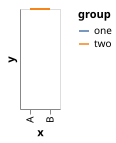

In [5]:
alt.renderers.enable("svg")#, show_warnings=True)

import altair as alt



data = alt.Data(
    values=[
        {"x": "A", "y": 1, "group": "one"},
        {"x": "A", "y": 2, "group": "two"},
        {"x": "B", "y": 2, "group": "one"},
        {"x": "B", "y": 3, "group": "two"},
    ]
)

chart = (
    alt.Chart(data, height=100)
    .mark_line()
    .encode(
        x="x:N",
        y=alt.Y(
            "y:Q",
            stack="zero",
            scale=alt.Scale(type="log"),
        ),
        color="group:N",
    )
)

chart
# chart.save("chart.svg")

In [ ]:
from importlib.metadata import version

version("vl-convert-python")
